# Dispersion Measure Gaussian Process: Injection and Recovery

This notebook injects dispersion measure (DM) variations into a simulated dataset with the NANOGrav 15-year array geometry, then recovers them with a DM Gaussian process (DMGP) alongside intrinsic pulsar red noise and an HD-correlated GWB.

The simulated dataset is built with [pta_sims](https://github.com/aiden-g12321/pta_sims), which draws the noise-weighted inner products **Prometheus** consumes (e.g. "TNr") directly from the model, so no TOAs are generated or refit.

### Requirements

- This notebook should be executed on a (NVIDIA) GPU with CUDA-enabled JAX.

- The analysis requires the packages imported in the following cell (including `pta_sims`), and other common packages.

- Single precision (`float32`) is used throughout, except for one matrix factorization in double precision (`float64`); see the README.

In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '1'

# to load/save objects
import json
import pickle
from la_forge import core
from enterprise_extensions.load_feathers import load_feathers_from_folder

# for plotting
import numpy as np
import matplotlib.pyplot as plt
from iris import Iris

# for sampling
import jax
import jax.numpy as jnp
import jax.random as jr
import numpyro

# to simulate data
import pta_sims

# prometheus objects
from prometheus import data
from prometheus.data import FourierBasis
from prometheus.spectral_models import IndependentSpectralModel, CommonSpectralModel
from prometheus import spectra
from prometheus.pta_model import PTAModel
from prometheus import utilities as utils

%load_ext autoreload
%autoreload 2

libstempo not installed. PINT or libstempo are required to use par and tim files.


In [2]:
# check that we are running on a GPU
# this should print something like "CudaDevice(id=...)"
print(jax.devices())

[CudaDevice(id=0)]


## Load Data

DM variations delay a TOA by an amount proportional to $\nu^{-2}$, where $\nu$ is its radio frequency. A DMGP therefore lives on its own Fourier basis, the usual one scaled per TOA:
\begin{equation}
    F_\text{DM} = F \left(\frac{\nu_\text{ref}}{\nu}\right)^2,
\end{equation}
with $\nu_\text{ref} = 1400$ MHz by default. **Prometheus** handles any such basis the same way: besides the achromatic pulsar noise basis (named `'red'`, with `nfreqs` frequency bins), the `prometheus.data.Data` object accepts a list of `prometheus.data.FourierBasis` objects (`extra_bases`), each with a name, a number of frequency bins and a chromatic index (0 for achromatic processes, 2 for DM variations, 4 for scattering). The noise-weighted inner products between all bases are computed once, when the `Data` object is built, and spectral models then refer to a basis by name. (`nfreqs_dm=30` is a shorthand for the DM basis below.)

The NANOGrav 15-year timing models absorb DM variations with DMX: one free DM offset in each $\sim$6-day window. These timing-model parameters are analytically marginalized, so DMX projects out nearly all of the DM signal a DMGP would model (and the two are degenerate). As in analyses that replace DMX with a DMGP, we remove the DMX columns from the timing-model design matrix of each pulsar before building the `Data` object. The DM, DM1, DM2 parameters remain in the timing model.

We'll load the pulsar objects and white noise dictionary (obtained from the [NANOGrav 15-year stochastic analysis GitHub repository](https://github.com/nanograv/15yr_stochastic_analysis/tree/main/tutorials/data)).

In [3]:
# load feather pulsar objects
psrs = load_feathers_from_folder('../data/NG15/feathers')

# load white noise dictionary
with open('../data/NG15/15yr_wn_dict.json', 'r') as fp:
    wn_dict = json.load(fp)

FeatherPulsar.read_feather: cannot find fitpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J1312+0051.feather.
FeatherPulsar.read_feather: cannot find setpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J1312+0051.feather.
FeatherPulsar.read_feather: cannot find _pdist in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J1312+0051.feather.
FeatherPulsar.read_feather: cannot find fitpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J0613-0200.feather.
FeatherPulsar.read_feather: cannot find setpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J0613-0200.feather.
FeatherPulsar.read_feather: cannot find _pdist in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J0613-0200.feather.
FeatherPulsar.read_feather: cannot find fitpars in feather file ../data/NG15/feathers/v1p1_de440_pint_bipm2019-J0610-2100.feather.
FeatherPulsar.read_feather: cannot find setpars in feather file ../data/NG15/feathers

In [4]:
def dmx_columns(psr):
    """
    Indices of the timing-model design matrix columns for DMX parameters:
    those which are non-zero only for TOAs inside a single DMX window.
    """
    mjds = psr.toas / 86400.
    nonzero = psr.Mmat != 0
    windows = [(dmx['DMXR1'], dmx['DMXR2']) for dmx in psr.dmx.values()]
    cols = []
    for j in range(psr.Mmat.shape[1]):
        t = mjds[nonzero[:, j]]
        if 0 < len(t) < len(mjds) and any(t.min() >= r1 - 1e-3 and t.max() <= r2 + 1e-3 for r1, r2 in windows):
            cols.append(j)
    return np.array(cols, dtype=int)

# remove DMX from the timing model of every pulsar
ndmx = []
for psr in psrs:
    cols = dmx_columns(psr)
    psr.Mmat = np.delete(psr.Mmat, cols, axis=1)
    ndmx.append(len(cols))
print(f'removed {sum(ndmx)} DMX columns in total')
print(f'{psrs[0].name}: removed {ndmx[0]} DMX columns, {psrs[0].Mmat.shape[1]} timing-model parameters remain')

removed 7408 DMX columns in total
J1312+0051: removed 48 DMX columns, 14 timing-model parameters remain


In [5]:
# now we can construct the prometheus.data.Data object with a DM basis
# (30 frequency bins for both the pulsar noise basis 'red' and the DM basis 'dm')
NG15_data = data.Data(name='NG15_noDMX',
                      psrs=psrs,
                      wn_dict=wn_dict,
                      nfreqs=30,
                      extra_bases=[FourierBasis('dm', nfreqs=30, chromatic_index=2)])
print(type(NG15_data))

building pulsar models: 100%|██████████| 67/67 [00:21<00:00,  3.14it/s, running J0437-4715]


<class 'prometheus.data.Data'>


In [6]:
# save the data object for future analyses
NG15_data.save_data(filepath='../data/NG15/data_dm_noDMX.pkl')

# or load a previously constructed data object
# with open('../data/NG15/data_dm_noDMX.pkl', 'rb') as fp:
#     NG15_data = pickle.load(fp)

Saved data object to ../data/NG15/data_dm_noDMX.pkl.


In [7]:
# the data object contains useful attributes
print(f'number of pulsars in array = {NG15_data.npsrs}')
print(f'Fourier bases = {NG15_data.basis_names}')
print(f'DM basis = {NG15_data.get_basis("dm")}')

number of pulsars in array = 67
Fourier bases = ['red', 'dm']
DM basis = FourierBasis('dm', nfreqs=30, chromatic_index=2, fref=1400, Tspan=None)


## Construct Spectral Models

As in the `gwb_pe.ipynb` notebook, we model the intrinsic pulsar noise with a `prometheus.spectral_models.IndependentSpectralModel` and the GWB with a `prometheus.spectral_models.CommonSpectralModel`. The DM variations are just another per-pulsar process:
- They are modeled with an `IndependentSpectralModel` (the same spectral model is applied independently to every pulsar) on the `'dm'` basis, so its Fourier coefficients multiply $F_\text{DM}$. (`prometheus.spectral_models.DMSpectralModel` is a shorthand for this.)
- Following Enterprise, the coefficients are timing delays at $\nu_\text{ref}$, so a power law amplitude is that of the delay at 1400 MHz.
- Other per-pulsar processes (e.g. scattering on a basis with chromatic index 4) are added in exactly the same way.

In [8]:
# we'll model the pulsar noise with a power law
# the IndependentSpectralModel automatically applies this model to
# every pulsar in the array independently
psr_model = IndependentSpectralModel(name='psr_params',
                                     get_phi_diag_func=spectra.power_law,
                                     parameter_bounds=[[-20., -10.], # log10_amp bounds
                                                       [0., 7.]],    # spectral index bounds
                                     data=NG15_data)

# model the GWB with a power law and HD correlations
# also specify the number of frequency bins used in the GWB model
gwb_model = CommonSpectralModel(name='gwb_params',
                                get_phi_diag_func=spectra.power_law,
                                parameter_bounds=[[-20., -10.], # log10_amp bounds
                                                  [0., 7.]],    # spectral index bounds
                                correlation_matrix='HD',
                                data=NG15_data,
                                nfreqs=14)

# model the DM variations in each pulsar with a power law
# on all frequency bins of the DM basis
dm_model = IndependentSpectralModel(name='dm_params',
                                    get_phi_diag_func=spectra.power_law,
                                    parameter_bounds=[[-20., -10.], # log10_amp bounds
                                                      [0., 7.]],    # spectral index bounds
                                    data=NG15_data,
                                    basis='dm')

## Build a PTA Model

Now we put everything together in a `prometheus.pta_model.PTAModel` object, passing the per-pulsar processes as a list.

The intrinsic noise and DM variations live on different bases, so the `PTAModel` uses its `'marginalized'` sampling model (`PTAModel.sampling_model_marginalized`): the per-pulsar Fourier coefficients of the stacked basis $[F \,|\, F_\text{DM}]$ are marginalized analytically, and only the GWB Fourier coefficients are sampled, through a standardizing transform conditional on the marginalized per-pulsar processes. (The `'shared'` sampling model of the `gwb_pe.ipynb` notebook instead describes the GWB and intrinsic noise with one set of coefficients, which requires a single shared basis.)

In [9]:
# plug the per-pulsar processes (intrinsic noise and DM) and the GWB into the PTA model
pta_model = PTAModel(psr_model=[psr_model, dm_model],
                     gwb_model=gwb_model)
print(type(pta_model))
print(f'sampling model: {pta_model.sampling}')
print(f'stacked bases: {list(pta_model.stacked_bases())}')

<class 'prometheus.pta_model.PTAModel'>
sampling model: marginalized
stacked bases: ['red', 'dm']


## Simulate a dataset

We inject a power law GWB with HD correlations, intrinsic red noise in each pulsar at the median values of the NANOGrav 15-year analysis, and DM variations with power law parameters drawn at random for each pulsar. `pta_sims.simulate` takes the `PTAModel` and the injected hyper-parameters (in the same format as the samples), and returns a simulated `Data` object and the same `PTAModel` rebuilt with it.

In [10]:
# intrinsic red noise: medians of the NANOGrav 15-year Enterprise chain
enterprise_core = core.Core(corepath='chains/hd_14f_pl_vg.core')
psr_params_inj = np.array([[np.median(enterprise_core.get_param(f'{psr_name}_red_noise_log10_A')),
                            np.median(enterprise_core.get_param(f'{psr_name}_red_noise_gamma'))]
                           for psr_name in NG15_data.psr_names])

# GWB: power law with gamma = 13/3
gwb_params_inj = np.array([-14.4, 13. / 3.])

# DM variations: log10_amp in [-13.5, -12.5] and spectral index in [1, 4]
rng = np.random.default_rng(23782)
dm_params_inj = np.array([rng.uniform(-13.5, -12.5, NG15_data.npsrs),
                          rng.uniform(1., 4., NG15_data.npsrs)]).T

injection = {psr_model.name : psr_params_inj,
             gwb_model.name : gwb_params_inj,
             dm_model.name : dm_params_inj}

In [11]:
# simulate!
sim = pta_sims.simulate(pta_model,
                        params=injection,
                        seed=2026,
                        name='NG15_noDMX_sim')
print(sim.summary())

# the PTA model of the simulated dataset
sim_pta_model = sim.pta_model

Simulated dataset "NG15_noDMX_sim"
  pulsars 67, stochastic components 60, deterministic components 120
  white noise included: True
  joint Gram rank 37-123 of 240 (truncation rtol 1e-12)
  largest negative-eigenvalue fraction 3.69e-14  (float64 rounding floor ~1e-15; >1e-13 means the stored Gram matrix is itself no longer numerically PSD)
  trace discarded by truncation 1.11e-12
  float32 downcast into Data:
    FNrs     max rel err 5.75e-08, 0 non-finite, 0 underflowed to zero (range 3.52e-07 .. 4.45e+02)
    FNFs     max rel err 5.93e-08, 0 non-finite, 0 underflowed to zero (range 1.28e-13 .. 6.84e-02)
    TDNrs    max rel err 5.88e-08, 0 non-finite, 0 underflowed to zero (range 8.64e-09 .. 5.45e+02)
    TNTDs    max rel err 5.95e-08, 0 non-finite, 0 underflowed to zero (range 3.38e-16 .. 6.84e-02)
    TDNTDs   max rel err 5.95e-08, 0 non-finite, 0 underflowed to zero (range 2.34e-17 .. 6.84e-02)


## Sample the posterior!

As in the other examples, we use NumPyro's No U-Turn Sampler (NUTS) to sample the posterior.

The DM variations are loud (once DMX is removed, the expected signal-to-noise ratio of a DM process with $\log_{10} A_\text{DM} = -13$ reaches hundreds in the best pulsars), so most of the prior volume is very far from the posterior. NumPyro's default initialization (random points in the prior) then starts the sampler where the log-likelihood is $\sim 10^6$ below its maximum, and the step size collapses during warm-up. Instead we start from a generic point: the intrinsic noise at the NANOGrav 15-year values, and the same DM power law ($\log_{10} A_\text{DM} = -13$, $\gamma_\text{DM} = 2.5$) in every pulsar.

__WARNING__: On occasion, the NUTS sampler will warm-up in a non-representative region of parameter space, which causes poor sampling. You can identify this failure by examining the step-size after running for 100 HMC steps or so. If the step-size falls below $\sim 10^{-5}$, terminate the run and try again - this time with a different random seed.

In [12]:
# initial values of the sampler (see above)
init_values = {psr_model.name : jnp.array(psr_params_inj),
               gwb_model.name : jnp.array([-14.5, 13. / 3.]),
               dm_model.name : jnp.tile(jnp.array([-13., 2.5]), (NG15_data.npsrs, 1)),
               'z' : jnp.zeros((NG15_data.npsrs, 2 * gwb_model.nfreqs))}

# build the NumPyro NUTS kernel
nuts_kernel = numpyro.infer.NUTS(model=sim_pta_model.sampling_model,
                                 init_strategy=numpyro.infer.init_to_value(values=init_values))

# specify MCMC attributes
mcmc = numpyro.infer.MCMC(sampler=nuts_kernel,
                          num_warmup=1000,
                          num_samples=5000)

# seed to start sampling
# (see "WARNING" above: change if necessary)
seed = 1708100

# sample!
mcmc.run(jr.PRNGKey(seed), extra_fields=('diverging',))
samples = mcmc.get_samples()

sample: 100%|██████████| 6000/6000 [36:33<00:00,  2.74it/s, 127 steps of size 3.26e-02. acc. prob=0.95]  


In [13]:
# step size and number of divergent transitions
print(f"step size = {mcmc.last_state.adapt_state.step_size:.2e}")
print(f"divergent transitions = {int(mcmc.get_extra_fields()['diverging'].sum())} of {len(mcmc.get_extra_fields()['diverging'])}")

# uncomment to examine more sampling diagnostics
# (this is a long output because we sample
# ALL the GWB Fourier coefficients)

mcmc.print_summary()

step size = 3.26e-02
divergent transitions = 0 of 5000

                      mean       std    median      5.0%     95.0%     n_eff     r_hat
  dm_params[0,0]    -14.83      1.60    -14.53    -17.41    -12.63    618.73      1.00
  dm_params[0,1]      4.24      1.75      4.38      1.81      7.00   3190.38      1.00
  dm_params[1,0]    -13.24      0.05    -13.24    -13.33    -13.17   7260.97      1.00
  dm_params[1,1]      1.84      0.22      1.83      1.50      2.21   7749.15      1.00
  dm_params[2,0]    -17.18      1.77    -17.34    -20.00    -14.60   3862.67      1.00
  dm_params[2,1]      3.16      1.99      3.02      0.00      6.06   7376.87      1.00
  dm_params[3,0]    -13.05      0.07    -13.05    -13.17    -12.94   6211.55      1.00
  dm_params[3,1]      2.77      0.33      2.76      2.22      3.29   5965.62      1.00
  dm_params[4,0]    -13.10      0.43    -13.02    -13.78    -12.45   2429.19      1.00
  dm_params[4,1]      3.78      0.95      3.63      2.21      5.22   2351.

In [14]:
# save samples to feather file
utils.save_chain(samples_dict=samples,
                 filepath='chains/NG15sim_HD_PL_Nf14_DMGP.feather',
                 save_coeff_samples=False)

# we can also load samples
# samples = utils.load_chain('chains/NG15sim_HD_PL_Nf14_DMGP.feather')

Saved chain samples to chains/NG15sim_HD_PL_Nf14_DMGP.feather.


## Post-processing

Let's make some plots using Prometheus' companion plotting package `Iris`, with the injected values marked.

In [15]:
plotter = Iris(sim_pta_model, samples, truths=injection)

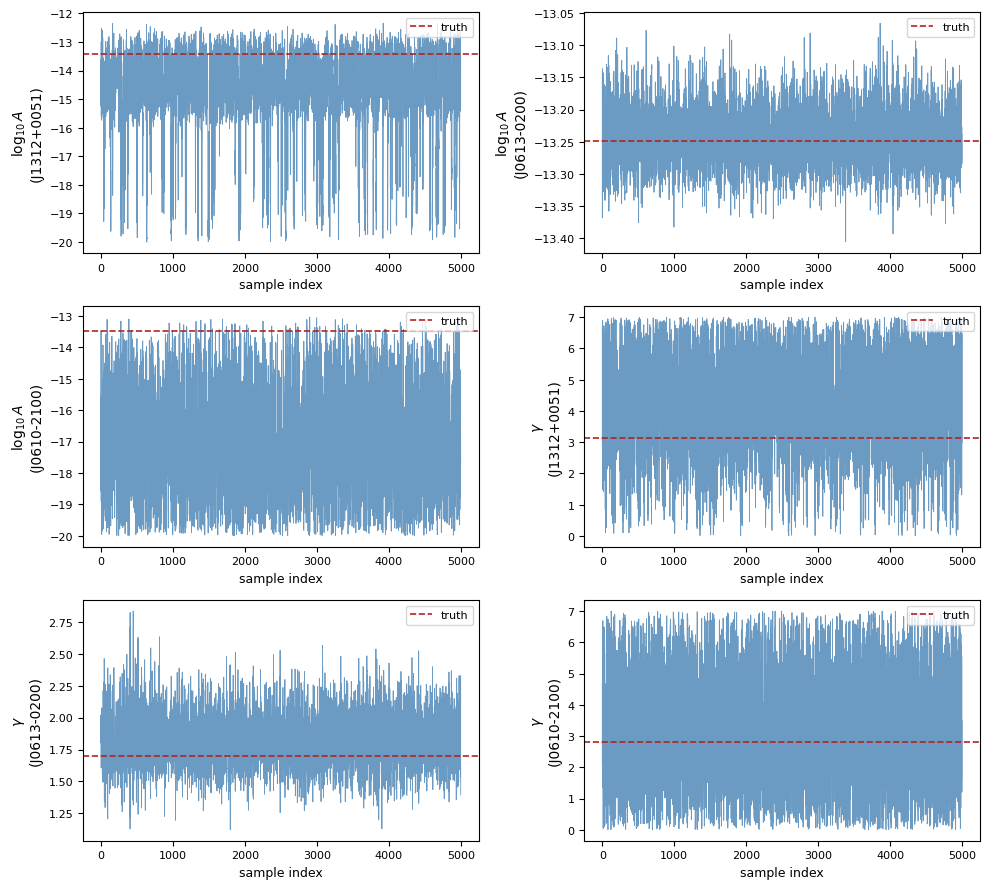

In [16]:
# DM parameters of the first few pulsars
dm_params_first_psrs = [p for p in plotter.params_for_key(dm_model.name)
                        if p in plotter.params_for_pulsars(list(range(3)))]
fig = plotter.trace(dm_params_first_psrs)

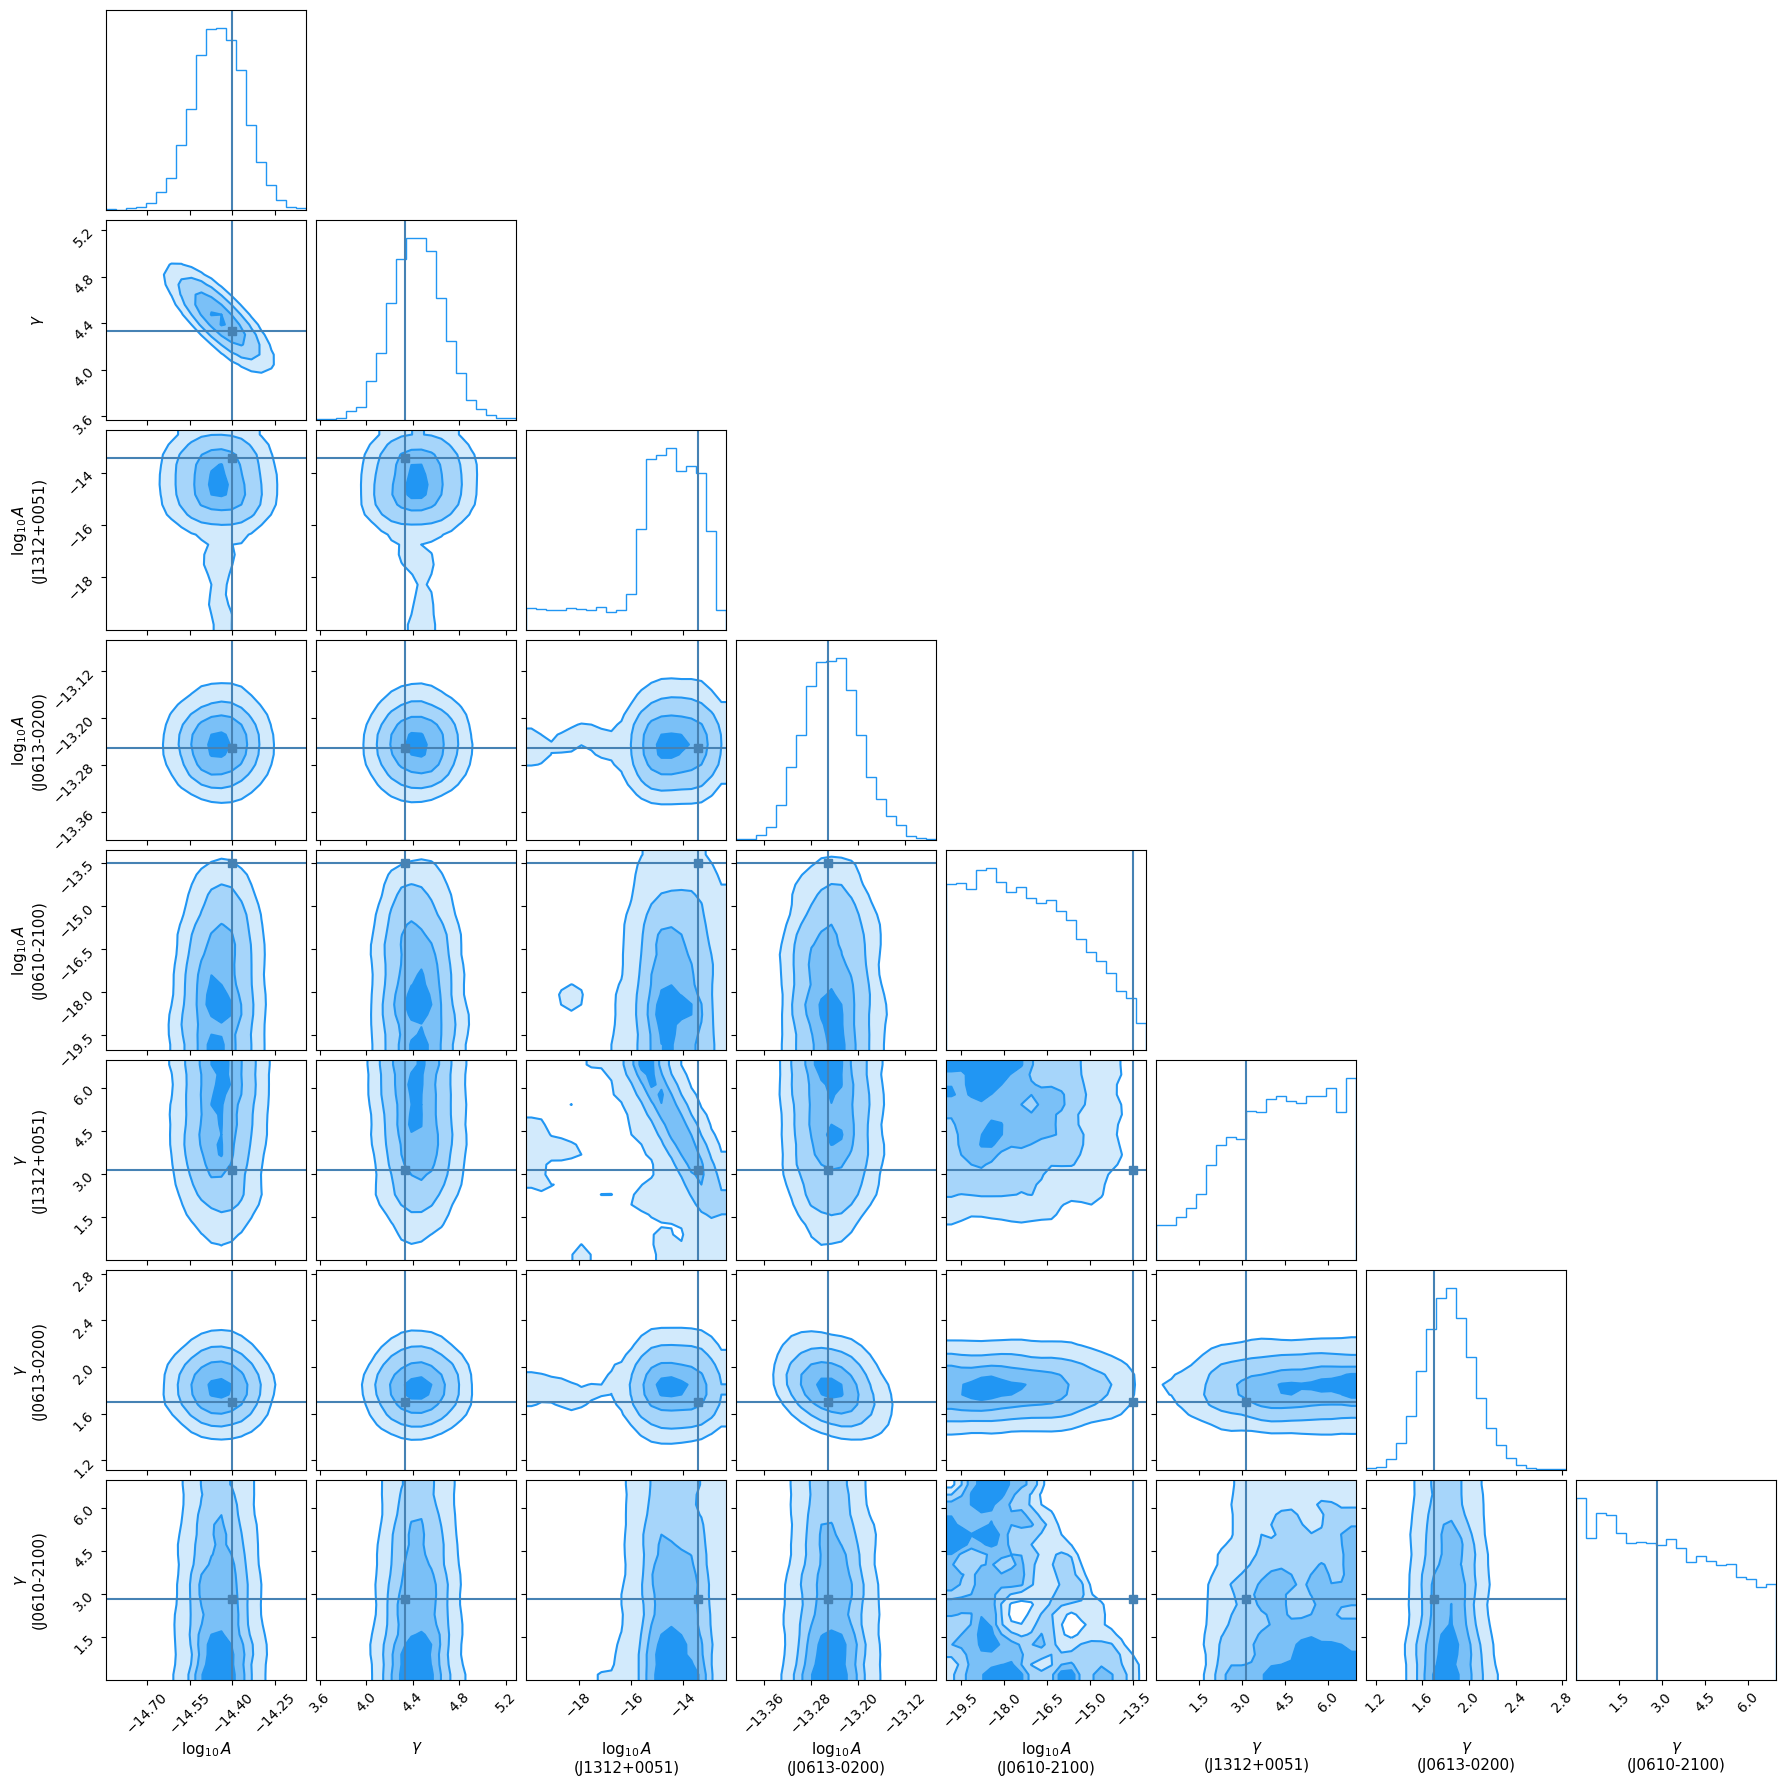

In [17]:
# GWB recovery and DM recovery in first few pulsars
fig = plotter.corner(params=plotter.gwb_model_params() + dm_params_first_psrs,
                     bins=20)

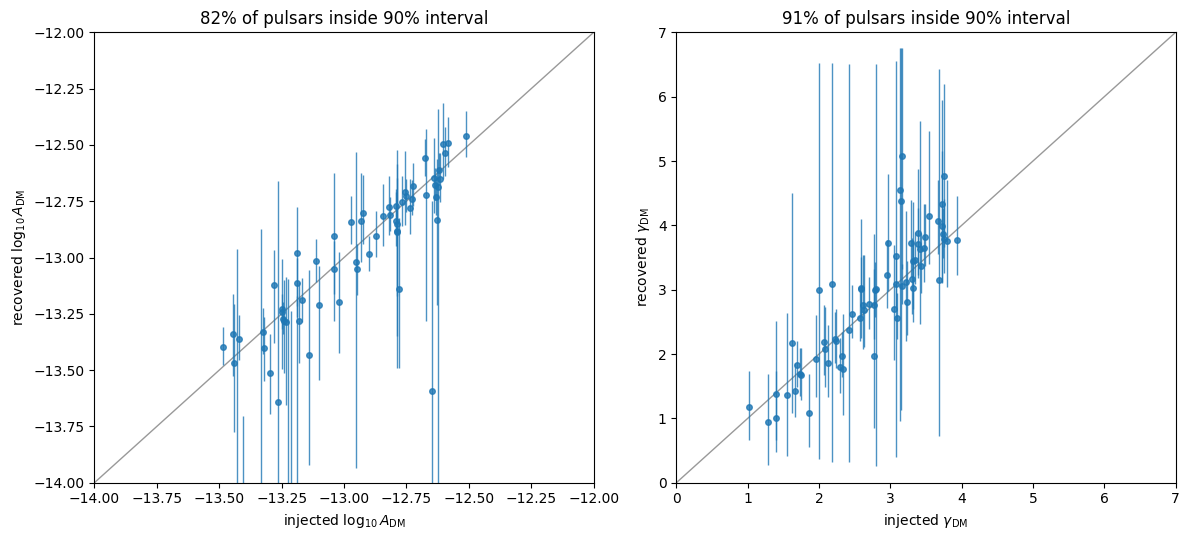

In [18]:
# DM recovery across the whole array: posterior median and 90% credible interval vs. injected value
dm_samples = np.array(samples[dm_model.name])          # (nsamples, npsrs, 2)
dm_median = np.median(dm_samples, axis=0)
dm_lo, dm_hi = np.percentile(dm_samples, [5., 95.], axis=0)

fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
for i, (ax, label) in enumerate(zip(axs, [r'$\log_{10} A_\mathrm{DM}$', r'$\gamma_\mathrm{DM}$'])):
    lims = [dm_model.param_mins[i], dm_model.param_maxs[i]] if i == 1 else [-14., -12.]
    ax.plot(lims, lims, color='0.6', lw=1, zorder=0)
    ax.errorbar(dm_params_inj[:, i], dm_median[:, i],
                yerr=[dm_median[:, i] - dm_lo[:, i], dm_hi[:, i] - dm_median[:, i]],
                fmt='o', ms=4, color='C0', ecolor='C0', elinewidth=1, alpha=0.8)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel(f'injected {label}')
    ax.set_ylabel(f'recovered {label}')
    coverage = np.mean((dm_lo[:, i] <= dm_params_inj[:, i]) & (dm_params_inj[:, i] <= dm_hi[:, i]))
    ax.set_title(f'{100 * coverage:.0f}% of pulsars inside 90% interval')
fig.tight_layout()